# 3.02 · MiBici reproducibility of the deployable model

**Phase 3 (deployment)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`. It runs after `3.01`, which served the champions with FastAPI.

- **Input:**
  - the reference set `tests/data/reference.json` and the `snapshot-<digest>` run it comes from (`make snapshot`)
  - the exported champions in `models/` and the feature table with the station profiles
  - the results of `make reproduce` in other environments, saved in `docs/reproducibility/`
  - the published image running (`docker run -p 8000:8000 racj90120hplmnv09/mibici-ml-service:0.1.1`) and the MLflow server (`make mlflow`)
- **Output:** nothing is written. The notebook compares the reference with what each environment reproduced.

**Why.** A model is only deployable if someone else can rebuild it and get the same numbers. Otherwise a change in a forecast cannot be told apart from a change in the environment. The rubric asks for the dependencies pinned, the seeds set, the model and its inputs versioned, and the pipeline and the service run in a clean environment and compared with the reference.

**Requisites:** `make mlflow` and the image running on port 8000. The refits take about two minutes per target.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import os

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # keep the outputs readable
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import mlflow
import numpy as np
import pandas as pd
from sklearn.base import clone

from team2_mlops2026 import plots
from team2_mlops2026.config import MLFLOW_TRACKING_URI, MODELS_DIR, PROJ_ROOT
from team2_mlops2026.features import FEATURES_DIR, SEED, TARGETS
from team2_mlops2026.modeling import export
from team2_mlops2026.modeling import reproducibility as rp
from team2_mlops2026.modeling.evaluate import segment_report
from team2_mlops2026.modeling.registry import model_name
from team2_mlops2026.modeling.train import load_training_data, model_inputs, report_metrics

plots.use_style()
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
client = mlflow.MlflowClient()
pd.set_option("display.max_colwidth", 70)

/Users/xaviermini/code/tec/mlops/finalProyecto/MLOps_Team2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-18 15:05:56.794 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: /Users/xaviermini/code/tec/mlops/finalProyecto/MLOps_Team2


## Parameters

In [3]:
SERVICE_URL = os.getenv("SERVICE_URL", "http://127.0.0.1:8000")  # the published image
RESULTS_DIR = PROJ_ROOT / "docs" / "reproducibility"  # make reproduce ... --save in other environments
THREADS = (-1, 4)  # LightGBM's n_jobs: all the cores (as trained), then 4
KEY_METRICS = ["overall_wape", "peak_wape", "overall_mae", "overall_poisson_deviance", "group_1_daily_wape"]
reference = rp.read_reference()

## 1. What is versioned

`make snapshot` logs one run with what the champions need to be rebuilt and checked: the feature table and the station profiles that trained them (Parquet files and digests), and the reference set. The registered versions point to it with the tag `snapshot_run`. A copy of the reference set, `tests/data/reference.json`, travels with the code, so another machine can compare without the MLflow server.

In [4]:
run = mlflow.get_run(reference["snapshot_run"])
artifacts = [
    (a.path, a.file_size / 1e6)
    for folder in (rp.SNAPSHOT_ARTIFACT, rp.REFERENCE_ARTIFACT)
    for a in client.list_artifacts(run.info.run_id, folder)
]
print(f"Run {run.info.run_name} ({run.info.run_id}), snapshot digest {reference['snapshot_digest']}")
display(pd.DataFrame(artifacts, columns=["artifact", "MB"]).set_index("artifact").round(2))

local = rp.table_digests(FEATURES_DIR)
versions = {
    target: client.get_model_version(entry["name"], entry["version"])
    for target, entry in reference["models"].items()
}
pd.DataFrame(
    {
        target: {
            "registered version": f"{v.name} v{v.version}",
            "tag snapshot_run": v.tags.get(rp.SNAPSHOT_TAG),
            "features digest (version)": v.tags["features_digest"],
            "features digest (snapshot)": reference["models"][target]["features_digest"],
            "features digest (local table)": local["features_digest"],
            "profiles digest (version)": v.tags["profiles_digest"],
            "profiles digest (local table)": local["profiles_digest"],
        }
        for target, v in versions.items()
    }
)

Run snapshot-373aa06d7db0 (ea0f152256134089863214a3cdd2e4b4), snapshot digest 373aa06d7db0c2573b67a54eb4d3c7e4


,MB
artifact,
snapshot/station_hour_features.parquet,101.31
snapshot/station_profiles.parquet,17.98
reference/reference.json,0.01


,departures,arrivals
registered version,mibici-departures v1,mibici-arrivals v1
tag snapshot_run,ea0f152256134089863214a3cdd2e4b4,ea0f152256134089863214a3cdd2e4b4
features digest (version),636e73295b9df173482041fd5cd04ede,636e73295b9df173482041fd5cd04ede
features digest (snapshot),636e73295b9df173482041fd5cd04ede,636e73295b9df173482041fd5cd04ede
features digest (local table),636e73295b9df173482041fd5cd04ede,636e73295b9df173482041fd5cd04ede
profiles digest (version),51c85bee5c1166854a6da55a41631c28,51c85bee5c1166854a6da55a41631c28
profiles digest (local table),51c85bee5c1166854a6da55a41631c28,51c85bee5c1166854a6da55a41631c28


In [5]:
lock = (PROJ_ROOT / "requirements-lock.txt").read_text().splitlines()
pins = [line for line in lock if "==" in line]
direct = [
    line
    for name in ("requirements.txt", "requirements-serving.txt")
    for line in (PROJ_ROOT / name).read_text().splitlines()
    if "==" in line
]
print(f"requirements-lock.txt: {len(pins)} packages pinned, {len(direct)} of them direct dependencies")
print("Seed of every random source: features.SEED =", SEED)

requirements-lock.txt: 186 packages pinned, 27 of them direct dependencies
Seed of every random source: features.SEED = 42


**Result → action.** Everything the champions need to be rebuilt is versioned, and it is the same everywhere:
- The `snapshot-373aa06d7db0` run holds the feature table (101 MB) and the station profiles (18 MB) that trained the champions, plus the reference set.
- Both registered versions (v1) point to it with the tag `snapshot_run`. The digests they recorded, the snapshot's and the local table's are the same: `636e7329…` for the features and `51c85bee…` for the profiles.
- `requirements-lock.txt` pins 186 packages, 27 of them direct dependencies, and one seed, `SEED = 42`, reaches every random source (ML Canvas §8).

→ From the registered version alone one reaches the tables that trained it (the `snapshot_run` tag), the code (the `git_commit` tag) and the outputs it must give (the reference set).

## 2. The environments

Each environment records where it ran: OS, CPU, Python, the versions of the packages that compute the forecasts, and the commit. The reference is the machine that created the snapshot. The others come from `make reproduce ... --save` (`docs/reproducibility/`), plus this machine.

In [6]:
saved = {}
for path in sorted(RESULTS_DIR.glob("*.json")):
    result = json.loads(path.read_text())
    saved.setdefault(path.stem.rsplit("-", 1)[0], []).append(result)

environments = {"reference (snapshot)": reference["environment"], "this machine": rp.environment()}
environments |= {name: results[0]["environment"] for name, results in saved.items()}
pd.DataFrame(environments)

,reference (snapshot),this machine,contenedor-linux
os,macOS-27.0.1-arm64-arm-64bit,macOS-27.0.1-arm64-arm-64bit,Linux-7.0.12-linuxkit-aarch64-with-glibc2.41
machine,arm64,arm64,aarch64
cpu,Apple M4 Pro,Apple M4 Pro,aarch64
cpu_count,12,12,12
container,False,False,True
python,3.12.12,3.12.12,3.12.12
numpy,2.5.4,2.5.4,2.5.4
pandas,3.1.0,3.1.0,3.1.0
pyarrow,25.0.1,25.0.1,25.0.1
scikit-learn,1.9.1,1.9.1,1.9.1


**Result → action.** Three environments, with the same package versions, from the lock:
- **reference:** the Mac that created the snapshot (macOS, Apple M4 Pro, 12 cores);
- **this machine:** the same Mac, at the commit of this branch;
- **contenedor-linux:** a clean Linux container (aarch64, glibc 2.41). It started from a fresh clone and ran `make requirements` with the lock, `make test` and `make reproduce`. Nothing of the host reached it but the feature table and the exported models, read-only.

They differ in the OS and its C library, which is what changes the last bits of the floating-point functions. → A teammate's machine adds a column with `make reproduce ... --save docs/reproducibility/<name>.json` (`docs/verificacion-fase3.md`).

## 3. Reference and reproduced test metrics, side by side

`compare()` refits each champion with its own params (an unfitted clone of the exported model) on the training split of the local table, after checking its digests, and scores it on the test split (2025-10 to 2026-09). It also scores the exported champion itself, so a difference in the data shows up apart from one in the training. The other environments did the same; their results are read from `docs/reproducibility/`.

In [7]:
here = rp.compare(retrain_models=True, url=SERVICE_URL)
print(rp.summary(here))

runs = {"this machine": here["retrain"]}
for name, results in saved.items():
    runs[name] = {t: r for result in results for t, r in result.get("retrain", {}).items()}

rows = []
for target in TARGETS:
    for metric in KEY_METRICS:
        row = {"target": target, "metric": metric, "reference": reference["models"][target]["test_metrics"][metric]}
        row |= {name: r[target]["metrics"][metric] for name, r in runs.items() if target in r}
        rows.append(row)
side_by_side = pd.DataFrame(rows).set_index(["target", "metric"])
side_by_side.style.format("{:.10f}")

OK   retrain departures (models:/mibici-departures/1): metrics within 1.4e-14 (exported model 0, tolerance 0.0001), forecasts within 8.2e-12 trips, fitted in 85 s
OK   retrain arrivals (models:/mibici-arrivals/1): metrics within 1.1e-13 (exported model 0, tolerance 0.0001), forecasts within 6.3e-11 trips, fitted in 38 s
OK   service http://127.0.0.1:8000: within 0


In [8]:
pd.DataFrame(
    {
        (name, target): {
            "max relative metric difference (refit)": r["max_metric_rel_diff"],
            "max relative metric difference (exported model)": r["exported_max_metric_rel_diff"],
            "max forecast difference (trips)": r["max_prediction_diff"],
            "tolerance": r["rtol"],
            "fit seconds": r["fit_seconds"],
            "passed": r["passed"],
        }
        for name, by_target in runs.items()
        for target, r in by_target.items()
    }
).T.style.format({"fit seconds": "{:.0f}"} | dict.fromkeys(
    [
        "max relative metric difference (refit)",
        "max relative metric difference (exported model)",
        "max forecast difference (trips)",
        "tolerance",
    ],
    "{:.2g}",
))

**Result → action.**
- **The exported champion** gives exactly the recorded test metrics on the local test split (difference 0) in both environments. The data and the model are the ones that were registered.
- **The refit** of the champion's params on the snapshot reproduces its test metrics:
  - within 1.4e-14 (departures) and 1.1e-13 (arrivals) on the Mac;
  - within 8.4e-15 and 1.5e-13 in the Linux container.
  That is about ten orders of magnitude inside the tolerance of 1e-4. The peak-hour WAPE is 0.5198 and 0.4831 in every environment.
- A refit takes between 40 s and 2 minutes per target, here and in the container.

→ The champion is reproducible. A teammate who gets a larger difference has other data or other packages, not noise, and `make reproduce` says which check failed.

## 4. The forecasts of a refit, and the number of threads

LightGBM builds a histogram of the gradients per thread and adds them up. With another number of threads the float sums run in another order, and now and then a split moves. This section refits the departures champion with all the cores, as it was trained, and with 4, and compares every test forecast with the registered model's.

In [9]:
target = "departures"
models, _ = export.load_exported(MODELS_DIR, [target])
champion = models[target]
train, test = load_training_data(FEATURES_DIR, reference["test_start"])
X_test = model_inputs(test)
registered = champion.predict(X_test)

differences, threads_metrics = {}, {}
for n_jobs in THREADS:
    refit = clone(champion).set_params(model__n_jobs=n_jobs).fit(model_inputs(train), train[target])
    forecast = refit.predict(X_test)
    label = "all cores" if n_jobs == -1 else f"{n_jobs} threads"
    differences[label] = np.abs(forecast - registered)
    metrics = report_metrics(segment_report(test, forecast, target, train))
    threads_metrics[label] = rp.metric_differences(metrics, reference["models"][target]["test_metrics"])

quantiles = [0.5, 0.9, 0.99, 0.999, 1.0]
table = pd.DataFrame({label: np.quantile(d, quantiles) for label, d in differences.items()}, index=quantiles)
table.index.name = "quantile of |refit - registered| (trips)"
table.loc["share identical"] = [float((d == 0).mean()) for d in differences.values()]
table.loc["max relative metric difference"] = [max(m.values()) for m in threads_metrics.values()]
table

,all cores,4 threads
quantile of |refit - registered| (trips),,
0.5,4.884981e-15,3.230749e-14
0.9,4.884981e-14,2.204903e-13
0.99,3.195222e-13,1.194600e-12
0.999,1.223608e-12,5.375256e-12
1.0,8.195666e-12,3.121303e-03
share identical,5.446951e-03,9.617858e-04
max relative metric difference,1.406323e-14,4.315193e-06


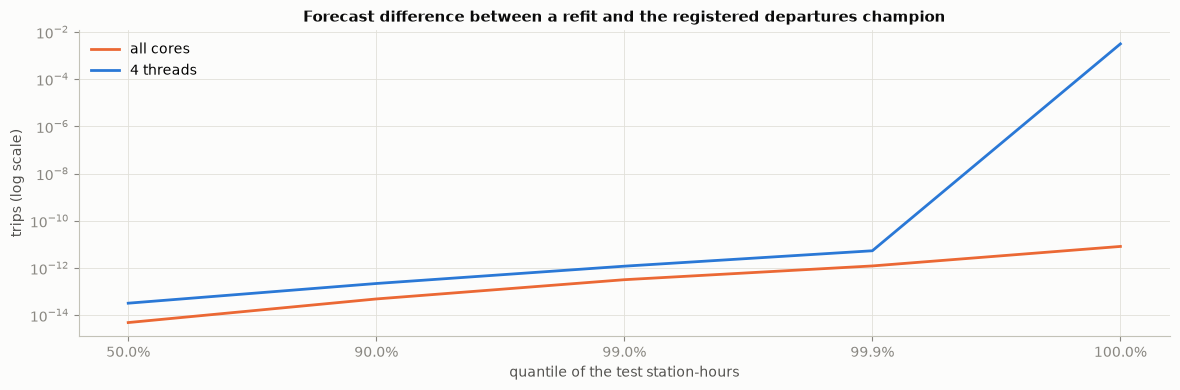

In [10]:
fig = plots.plot_lines(
    table.loc[quantiles].rename(index=lambda q: f"{q:.1%}").clip(lower=1e-16),
    f"Forecast difference between a refit and the registered {target} champion",
    "trips (log scale)",
    "quantile of the test station-hours",
)
fig.axes[0].set_yscale("log")

**Result → action.** The number of threads is the one source of variation left, and it is small:
- **With all the cores**, as the champion was trained, the refit's forecasts differ from the registered model's by at most 8.2e-12 trips. Only 0.5% of them are equal bit for bit; the rest differ in the last bits of the floating-point sums.
- **With 4 threads**, 99.9% of the forecasts are still within 5.4e-12 trips, but a few station-hours move by up to 0.003 trips, where a split landed elsewhere. The test metrics move by 4.3e-6.

→ This is why the tolerance of LightGBM is 1e-4 and not 0 (ML Canvas §8): a teammate with another number of cores reproduces the champion within it. A refit that is bit for bit on any machine needs a fixed `n_jobs` and `deterministic=True`, which is left for the next retraining because it would change the registered champion.

## 5. The service against the golden forecasts

The reference set holds request rows and the forecasts the champions gave for them. Any service that serves those versions, local or a container, must answer the same.

In [11]:
service = {"this machine": here.get("service")}
service |= {name: results[0].get("service") for name, results in saved.items()}
pd.DataFrame({name: s for name, s in service.items() if s}).T

,url,passed,max_diff,rows
this machine,http://127.0.0.1:8000,True,0.0,3
contenedor-linux,http://host.docker.internal:8000,True,0.0,3


**Result → action.** The service answers the reference rows with the golden forecasts, difference 0, both on this Mac (the image `0.1.1` on port 8000) and from the Linux container. Inference adds the same trees in the same order, so it does not depend on the number of threads. → `make reproduce --url` is the acceptance check of any deployment of the image.

## Findings and next steps

1. **Versioned.** The `snapshot-373aa06d7db0` run holds the tables that trained the champions and the reference outputs, and the registered versions point to it. `tests/data/reference.json` carries the reference set to any machine. `requirements-lock.txt` pins 186 packages, and one seed reaches every random source.
2. **Reproduced in a clean environment.** In a fresh Linux container the champions' test metrics are reproduced within 1.5e-13, and the exported champion gives exactly the recorded ones. The image from Docker Hub returns the golden forecasts.
3. **What is not bit for bit, and why.** LightGBM's refit depends on the number of threads: with 4 instead of 12, a few forecasts move by up to 0.003 trips and the metrics by 4.3e-6, inside the tolerance of 1e-4.
4. **Tolerances documented** per model, in `METRIC_RTOL` and in the ML Canvas §8.

Next steps:
- A teammate runs `make reproduce` on another machine, ideally Windows on x86, and adds the result to `docs/verificacion-fase3.md`.
- Fix `n_jobs` and set `deterministic=True` in the next retraining, so that a refit is bit for bit on any machine.
- Optionally, version the snapshot with DVC (#48), so a teammate can `dvc pull` the tables instead of rebuilding them.